# Демонстрація: ранжування вузлів графа знань дифузією

Короткий ноутбук для захисту, без нових експериментів. Варіанти дифузії — ті, що обрані в курсовій:
- запит з одним вузлом — PPR, α = 0.5, сирі оцінки (п. 6);
- пара вузлів — теплове ядро, t = 1, π/√d, добуток (п. 5).

Приклади ноутбук знаходить сам за детермінованим правилом, без ручного добору.

In [1]:
import time
from pathlib import Path
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reldiff.api import rank
from reldiff.multi import combine_scores
from reldiff import metaqa as MQ
from reldiff import metrics as M

T0 = time.perf_counter()
FIG = Path("../figures")
g, Q, P = MQ.load_processed("../data/metaqa", 500, 0)
deg = dict(g.degree())
PRIOR = ["movie", "actor", "director", "writer", "genre", "year", "language", "tag", "imdb_rating", "imdb_votes"]
UA = {"movie": "фільм", "actor": "актор", "director": "режисер", "writer": "сценарист", "genre": "жанр", "year": "рік",
      "language": "мова", "tag": "тег", "imdb_rating": "imdb", "imdb_votes": "imdb"}
kind = lambda v: UA[min(g.nodes[v]["kinds"], key=PRIOR.index)]
print(f"Підграф MetaQA: {g.number_of_nodes()} вузлів, {g.number_of_edges()} ребер")

Підграф MetaQA: 2957 вузлів, 5332 ребер


## 1. Багатоступінчасте питання: дифузія проти GraphRAG з k = 2

Серед перших 300 3-hop test-питань (у порядку qtype, номер рядка) беремо ті, для яких у 2-околі вузла запиту немає жодної відповіді, а серед топ-N дифузії з тим самим N = |2-окіл| відповідь є. З них обираємо питання, де найкраща відповідь дифузії стоїть найвище (при рівності — перше за порядком).

In [2]:
cand = Q[(Q["split"] == "test") & (Q["hop"] == 3)].sort_values(["qtype", "line"])
chosen, n_ok = None, 0
for row in cand.head(300).itertuples():
    rel = set(row.answers) - {row.topic}
    dist = nx.single_source_shortest_path_length(g, row.topic)
    N = sum(1 for v, d in dist.items() if 0 < d <= 2)
    if any(dist.get(a, np.inf) <= 2 for a in rel):
        continue
    s = rank(g, row.topic, "ppr", alpha=0.5)
    order = M.ranking(s, seeds=[row.topic])
    if rel & set(order[:N]):
        n_ok += 1
        best = min(order.index(a) for a in rel if a in order) + 1
        if chosen is None or best < chosen[0]:
            chosen = (best, row, rel, dist, N, s, order)
_, row, rel, dist, N, s, order = chosen
print(f"Питань з 300, де k-hop (k = 2) без відповіді, а дифузія з тим самим N її знаходить: {n_ok}")
print(f"Питання: {row.question}")
print(f"Тип питання: {row.qtype}; вузол запиту: «{row.topic}»; правильні відповіді: {sorted(rel)}")
print(f"Бюджет N = розмір 2-околу = {N}; відповідей у 2-околі: 0 (k-hop з k = 2 не знаходить жодної)")
pos = {v: i + 1 for i, v in enumerate(order)}
print(f"Ранги відповідей у дифузії: { {a: pos[a] for a in sorted(rel)} }; у топ-N: {sum(pos[a] <= N for a in rel)} з {len(rel)}")
top = pd.DataFrame([dict(ранг=i + 1, вузол=v, тип=kind(v), степінь=deg[v], відстань=dist.get(v), оцінка=s[v],
                         відповідь="✔" if v in rel else "") for i, v in enumerate(order[:10])])
top

Питань з 300, де k-hop (k = 2) без відповіді, а дифузія з тим самим N її знаходить: 124
Питання: what were the release years of the movies that share directors with the movie [Walking and Talking]
Тип питання: movie_to_director_to_movie_to_year; вузол запиту: «Walking and Talking»; правильні відповіді: ['2010']
Бюджет N = розмір 2-околу = 35; відповідей у 2-околі: 0 (k-hop з k = 2 не знаходить жодної)
Ранги відповідей у дифузії: {'2010': 9}; у топ-N: 1 з 1


,ранг,вузол,тип,степінь,відстань,оцінка,відповідь
0,1,Nicole Holofcener,режисер,4,1,0.095918,
1,2,Catherine Keener,актор,14,1,0.049283,
2,3,nicole holofcener,тег,2,1,0.047959,
3,4,1996,рік,17,1,0.047225,
4,5,Anne Heche,актор,2,1,0.046504,
5,6,Please Give,фільм,10,2,0.041269,
6,7,Prozac Nation,фільм,11,2,0.013399,
7,8,Comedy,жанр,163,3,0.003387,
8,9,2010,рік,13,3,0.002256,✔
9,10,Cyrus,фільм,14,2,0.002144,


## 2. Пара акторів: оракул проти дифузії при пропущеному ребрі

Беремо першу пару актор + актор з вибірки п. 5 (seed = 0), де обидва актори мають щонайменше 2 ребра (тож видалення одного не ізолює вузол) і одну правильну відповідь. Видаляємо ребро «перший актор — спільний фільм», тобто моделюємо пропущену при вилученні трійку.

In [3]:
rng = np.random.default_rng(0)
smp = pd.concat([grp.iloc[np.sort(rng.choice(len(grp), min(300, len(grp)), replace=False))]
                 for _, grp in P.groupby("kind", sort=True)])
p = next(x for x in smp[smp["kind"] == "actor_actor"].itertuples()
         if x.n_answers == 1 and deg[x.seed_1] >= 2 and deg[x.seed_2] >= 2)
movie = p.answers[0]
edges = pd.read_csv("../data/metaqa/processed/movies500_seed0/subgraph_edges.csv", dtype=str, keep_default_na=False)
tr = [t for t in edges.itertuples(index=False, name=None) if not (t[0] == movie and t[2] == p.seed_1)]
g_cut = MQ.to_graph(tr)
print(f"Пара: «{p.seed_1}» + «{p.seed_2}»; спільний фільм: «{movie}»; видалено ребро «{p.seed_1}» — «{movie}»")

def show(gg, label):
    seeds = [p.seed_1, p.seed_2]
    orc = rank(gg, seeds, "k_hop", hops=1, agg="max")
    diff = combine_scores([rank(gg, q, "heat", t=1.0, normalize="sqrt_degree") for q in seeds], "product")
    o_order = M.ranking(orc, seeds=seeds); d_order = M.ranking(diff, seeds=seeds)
    o_rank = o_order.index(movie) + 1 if movie in o_order else None
    print(f"{label}: оракул (спільні сусіди запитів) відібрав {len(o_order)} вузл(и) {o_order[:5]}; "
          f"ранг фільму в оракула: {o_rank if o_rank else 'не відібрано'}; ранг фільму в дифузії: {d_order.index(movie) + 1}")
    return d_order, diff

d0, _ = show(g, "Повний граф")
d1, diff1 = show(g_cut, "Без ребра")
pd.DataFrame([dict(ранг=i + 1, вузол=v, тип=kind(v), оцінка=diff1[v], спільний_фільм="✔" if v == movie else "")
              for i, v in enumerate(d1[:5])])

Пара: «Adrienne Shelly» + «Liana Liberato»; спільний фільм: «Trust»; видалено ребро «Adrienne Shelly» — «Trust»
Повний граф: оракул (спільні сусіди запитів) відібрав 1 вузл(и) ['Trust']; ранг фільму в оракула: 1; ранг фільму в дифузії: 1
Без ребра: оракул (спільні сусіди запитів) відібрав 0 вузл(и) []; ранг фільму в оракула: не відібрано; ранг фільму в дифузії: 3


,ранг,вузол,тип,оцінка,спільний_фільм
0,1,adrienne shelly,тег,4.797245e-05,
1,2,Waitress,фільм,3.419065e-05,
2,3,Trust,фільм,3.330563e-05,✔
3,4,Comedy,жанр,9.521203e-07,
4,5,Drama,жанр,6.524111e-07,


## 3. Підграф навколо запиту з прикладу 1

Вузли: запит, правильні відповіді, по одному найкоротшому шляху від запиту до кожної відповіді і 25 найвищих вузлів дифузії. Колір — log₁₀ оцінки PPR. Запит позначено зіркою, відповіді — червоною обвідкою.

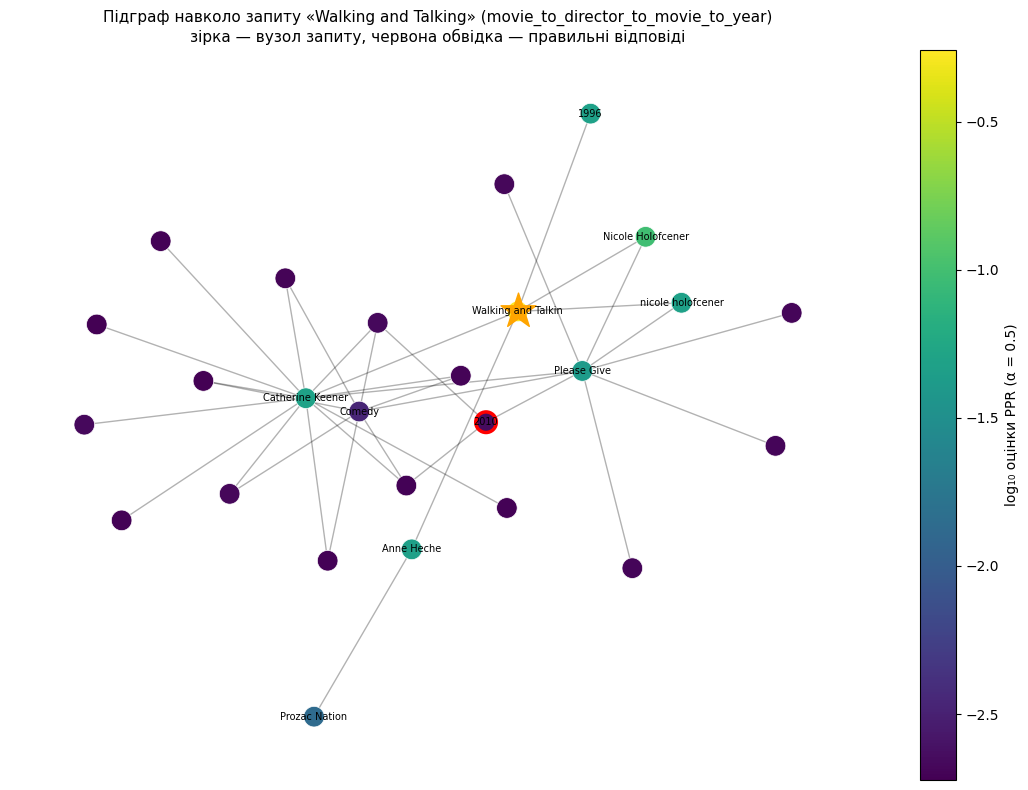

Час виконання ноутбука: 3.4 с


In [4]:
nodes = {row.topic} | set(rel) | set(order[:25])
for a in rel:
    nodes |= set(nx.shortest_path(g, row.topic, a))
H = nx.Graph(g.subgraph(nodes))
posn = nx.spring_layout(H, seed=1, k=0.6)
vals = np.log10(np.array([max(s[v], 1e-12) for v in H.nodes()]))
fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(H, posn, ax=ax, alpha=0.3)
sc = nx.draw_networkx_nodes(H, posn, ax=ax, node_color=vals, cmap="viridis", node_size=220,
                            edgecolors=["red" if v in rel else "white" for v in H.nodes()],
                            linewidths=[2.5 if v in rel else 0.5 for v in H.nodes()])
nx.draw_networkx_nodes(H, posn, nodelist=[row.topic], ax=ax, node_shape="*", node_size=700, node_color="orange")
nx.draw_networkx_labels(H, posn, labels={v: v[:18] for v in H.nodes() if v in rel or v == row.topic or v in order[:8]},
                        font_size=7, ax=ax)
plt.colorbar(sc, ax=ax, label="log₁₀ оцінки PPR (α = 0.5)")
ax.set_title(f"Підграф навколо запиту «{row.topic}» ({row.qtype})\nзірка — вузол запиту, червона обвідка — правильні відповіді", fontsize=11)
ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "08_demo_pidgraf.png", dpi=200); plt.show()
print(f"Час виконання ноутбука: {time.perf_counter() - T0:.1f} с")